# 29C — Persistent-Source Spatial + Wind Refinement
## Supervisor follow-up: distinguish continuation-like hotspots from spatially isolated anomalies

### Research idea

This notebook implements the supervisor/user interpretation more directly:

> If a new hotspot appears **near a source area that has already been active for several days**, the new point may be a continuation-like / propagation-like event. If a new hotspot appears **far from any persistent recent source**, it is a stronger contextual anomaly candidate.

The notebook therefore refines only the **Emerging-3 robust GeoMAE anomalies**.

```text
GeoMAE robust anomaly
        ↓
Emerging-3?
        ↓ yes
Find persistent source cells in t-3 ... t-1
(source active on at least 2 of 3 days)
        ↓
Is a persistent source nearby?
        ├─ no  → isolated from persistent source → HIGH PRIORITY
        └─ yes
             ↓
      was source active on t-1
      and wind points toward candidate?
             ├─ yes → persistent continuation-like → DEPRIORITIZE
             └─ no  → nearby persistent source, but ambiguous → RETAIN
```

### Important interpretation

- `persistent source` means repeated **FIRMS hotspot detection activity in the same 0.25° source cell**, not proof that the exact same physical fire continuously burned.
- `continuation-like` is a contextual explanation, **not confirmed fire spread**.
- `isolated` means far from persistent recent hotspot context at this grid scale. It does **not** prove anthropogenic or intentional ignition.
- We do not call deprioritized candidates ground-truth false positives because no anomaly ground-truth label is available.

### Primary working rule

- source persistence window: `t-3 ... t-1`;
- persistent source: active on **≥ 2 of 3 days**;
- nearby radius: **40 km**;
- wind support: source is active at `t-1` and cosine alignment **≥ 0.5** toward candidate;
- final high-priority candidate: Emerging robust anomaly with **no persistent source within 40 km**.

Sensitivity analysis checks 30/40/50 km, 2/3 vs 3/3 persistence, and wind alignment thresholds.

In [20]:
# 1. Imports

from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 300)
pd.set_option("display.width", 240)

In [21]:
# 2. Resolve project paths

cwd = Path.cwd()

candidate_roots = [
    cwd,
    cwd.parent,
    Path("/content/skripsi-karhut"),
    Path("/content/drive/MyDrive/skripsi-karhut"),
]

PROJECT_ROOT = None

for root in candidate_roots:
    data_path = (
        root / "data" / "processed" / "regional_025"
        / "karhut_ml_dataset_regional_025.csv"
    )
    nb25_dir = (
        root / "model_results" / "final_masked_temporal_anomaly"
        / "t2" / "exports"
    )
    required = [
        data_path,
        nb25_dir / "august_all_cells_multiseed_scores.csv",
        nb25_dir / "august_final_robust_anomaly_candidates.csv",
        nb25_dir / "august_hotspot_candidate_analysis.csv",
    ]

    if all(p.exists() for p in required):
        PROJECT_ROOT = root
        break

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate the regional dataset and NB25 exports. "
        "Run this notebook from the skripsi-karhut project root or set PROJECT_ROOT manually."
    )

DATA_PATH = (
    PROJECT_ROOT / "data" / "processed" / "regional_025"
    / "karhut_ml_dataset_regional_025.csv"
)

NB25_EXPORT_DIR = (
    PROJECT_ROOT / "model_results" / "final_masked_temporal_anomaly"
    / "t2" / "exports"
)

RESULT_DIR = (
    PROJECT_ROOT / "model_results"
    / "persistent_source_spatial_wind_refinement" / "t2"
)
EXPORT_DIR = RESULT_DIR / "exports"
FIGURE_DIR = RESULT_DIR / "figures"

EXPORT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

print("PROJECT_ROOT:", PROJECT_ROOT)
print("RESULT_DIR  :", RESULT_DIR)

PROJECT_ROOT: c:\Users\Asus\Documents\skripsi-karhut
RESULT_DIR  : c:\Users\Asus\Documents\skripsi-karhut\model_results\persistent_source_spatial_wind_refinement\t2


In [22]:
# 3. Fixed primary configuration

LOOKBACK_DAYS = 3
MIN_ACTIVE_DAYS_PERSISTENT = 2
NEAR_RADIUS_KM = 40.0
WIND_ALIGNMENT_THRESHOLD = 0.5
MIN_WIND_SPEED = 0.5

PREFERRED_TARGET_DATE = pd.Timestamp("2026-08-02")

print("LOOKBACK_DAYS                 :", LOOKBACK_DAYS)
print("MIN_ACTIVE_DAYS_PERSISTENT    :", MIN_ACTIVE_DAYS_PERSISTENT)
print("NEAR_RADIUS_KM                :", NEAR_RADIUS_KM)
print("WIND_ALIGNMENT_THRESHOLD      :", WIND_ALIGNMENT_THRESHOLD)
print("MIN_WIND_SPEED                :", MIN_WIND_SPEED)

LOOKBACK_DAYS                 : 3
MIN_ACTIVE_DAYS_PERSISTENT    : 2
NEAR_RADIUS_KM                : 40.0
WIND_ALIGNMENT_THRESHOLD      : 0.5
MIN_WIND_SPEED                : 0.5


In [23]:
# 4. Load regional data + frozen NB25 outputs

regional = pd.read_csv(DATA_PATH, parse_dates=["date"])

scores = pd.read_csv(
    NB25_EXPORT_DIR / "august_all_cells_multiseed_scores.csv",
    parse_dates=["date"],
)

candidates = pd.read_csv(
    NB25_EXPORT_DIR / "august_final_robust_anomaly_candidates.csv",
    parse_dates=["date"],
)

analysis = pd.read_csv(
    NB25_EXPORT_DIR / "august_hotspot_candidate_analysis.csv",
    parse_dates=["event_date"],
)

required_regional = {
    "date", "cell_id", "grid_lat", "grid_lon",
    "fire_active", "fire_count", "frp_sum",
    "wind_u_mean", "wind_v_mean",
}
missing = sorted(required_regional - set(regional.columns))
if missing:
    raise ValueError(
        "Regional dataset is missing required columns:\n"
        + "\n".join(f"- {c}" for c in missing)
    )

if "research_group" not in analysis.columns:
    raise ValueError(
        "NB25 candidate analysis has no research_group column. "
        "Run the NB23C/NB25 merge successfully first."
    )

group_info = (
    analysis[["event_date", "cell_id", "research_group"]]
    .drop_duplicates(["event_date", "cell_id"])
    .rename(columns={"event_date": "date"})
)

candidates = candidates.merge(
    group_info,
    on=["date", "cell_id"],
    how="left",
    validate="one_to_one",
)

regional = regional.sort_values(["date", "cell_id"]).reset_index(drop=True)
scores = scores.sort_values(["date", "cell_id"]).reset_index(drop=True)
candidates = candidates.sort_values(["date", "cell_id"]).reset_index(drop=True)

print("Regional rows          :", len(regional))
print("Regional cells         :", regional["cell_id"].nunique())
print("All robust anomalies   :", len(candidates))
print("August score rows      :", len(scores))
print()
print("Robust candidate composition:")
display(
    candidates["research_group"]
    .value_counts(dropna=False)
    .rename_axis("research_group")
    .reset_index(name="robust_candidates")
)

Regional rows          : 16625
Regional cells         : 133
All robust anomalies   : 620
August score rows      : 4123

Robust candidate composition:


,research_group,robust_candidates
0,Persistent,476
1,Emerging-3,118
2,NaN,26


# PART A — Refine only the Emerging-3 robust subset

The supervisor's specific question is about a hotspot that **appears newly** and whether it is close to an already-active source.

Therefore:
- all GeoMAE robust anomalies remain preserved;
- Persistent robust anomalies are not discarded — they answer a different question;
- only `Emerging-3` robust anomalies enter this persistent-source refinement.

In [24]:
# 5. Emerging robust-anomaly subset

emerging = candidates[candidates["research_group"].eq("Emerging-3")].copy()
persistent_robust = candidates[candidates["research_group"].eq("Persistent")].copy()
unknown_robust = candidates[
    ~candidates["research_group"].isin(["Emerging-3", "Persistent"])
].copy()

print("All robust anomalies :", len(candidates))
print("Emerging-3 robust    :", len(emerging))
print("Persistent robust    :", len(persistent_robust))
print("Unknown group        :", len(unknown_robust))

if emerging.empty:
    raise RuntimeError("No Emerging-3 robust anomaly candidates were found.")

All robust anomalies : 620
Emerging-3 robust    : 118
Persistent robust    : 476
Unknown group        : 26


In [25]:
# 6. Geometry helpers

EARTH_RADIUS_KM = 6371.0088


def haversine_km(lat1, lon1, lat2, lon2):
    lat1 = np.radians(np.asarray(lat1, dtype=float))
    lon1 = np.radians(np.asarray(lon1, dtype=float))
    lat2 = np.radians(np.asarray(lat2, dtype=float))
    lon2 = np.radians(np.asarray(lon2, dtype=float))

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2.0) ** 2
        + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2.0) ** 2
    )

    return 2.0 * EARTH_RADIUS_KM * np.arcsin(
        np.sqrt(np.clip(a, 0.0, 1.0))
    )


def source_to_target_unit(source_lat, source_lon, target_lat, target_lon):
    mean_lat_rad = np.radians(
        (float(source_lat) + float(target_lat)) / 2.0
    )

    east_km = (
        (float(target_lon) - float(source_lon))
        * 111.320
        * np.cos(mean_lat_rad)
    )
    north_km = (
        (float(target_lat) - float(source_lat))
        * 110.574
    )

    norm = float(np.hypot(east_km, north_km))
    if norm == 0:
        return np.nan, np.nan

    return east_km / norm, north_km / norm


def wind_alignment(source_u, source_v, east_unit, north_unit):
    if not np.isfinite(east_unit) or not np.isfinite(north_unit):
        return np.nan

    magnitude = float(np.hypot(source_u, source_v))
    if not np.isfinite(magnitude) or magnitude < MIN_WIND_SPEED:
        return np.nan

    return float(
        (
            float(source_u) * float(east_unit)
            + float(source_v) * float(north_unit)
        )
        / magnitude
    )

# PART B — Define a persistent source

For each candidate date `t`, inspect every regional source cell during:

```text
t-3, t-2, t-1
```

A source cell is called **persistent** when FIRMS activity is detected on at least **2 of those 3 days**.

This deliberately uses repeated hotspot activity rather than one isolated previous-day point.

For every persistent source we also record:
- whether it is still active at `t-1`;
- total recent fire count / FRP;
- distance to the Emerging candidate;
- wind alignment at `t-1` from source toward candidate.

In [26]:
# 7. Build persistent source tables for every Emerging candidate date

unique_candidate_dates = sorted(pd.to_datetime(emerging["date"].unique()))
source_tables = {}

for cand_date in unique_candidate_dates:
    cand_date = pd.Timestamp(cand_date)
    prior_dates = [
        cand_date - pd.Timedelta(days=lag)
        for lag in range(1, LOOKBACK_DAYS + 1)
    ]

    hist = regional[regional["date"].isin(prior_dates)].copy()

    if hist.empty:
        source_tables[cand_date] = pd.DataFrame()
        continue

    base = (
        hist
        .groupby(["cell_id", "grid_lat", "grid_lon"], as_index=False)
        .agg(
            active_days_prev3=("fire_active", "sum"),
            fire_count_prev3_sum=("fire_count", "sum"),
            frp_prev3_sum=("frp_sum", "sum"),
        )
    )

    t1 = (
        regional[regional["date"].eq(cand_date - pd.Timedelta(days=1))][
            [
                "cell_id",
                "fire_active",
                "fire_count",
                "frp_sum",
                "wind_u_mean",
                "wind_v_mean",
            ]
        ]
        .rename(
            columns={
                "fire_active": "active_t1",
                "fire_count": "fire_count_t1",
                "frp_sum": "frp_sum_t1",
                "wind_u_mean": "wind_u_t1",
                "wind_v_mean": "wind_v_t1",
            }
        )
    )

    base = base.merge(
        t1,
        on="cell_id",
        how="left",
        validate="one_to_one",
    )

    base["is_persistent_source"] = (
        base["active_days_prev3"] >= MIN_ACTIVE_DAYS_PERSISTENT
    )

    source_tables[cand_date] = base[
        base["is_persistent_source"]
    ].copy()

print("Candidate dates:", len(unique_candidate_dates))
print(
    "Median persistent source cells/date:",
    np.median([len(v) for v in source_tables.values()]),
)

Candidate dates: 27
Median persistent source cells/date: 65.0


In [27]:
# 8. Build candidate ↔ persistent-source evidence pairs

pair_rows = []

for cand in emerging.itertuples(index=False):
    cand_date = pd.Timestamp(cand.date)
    source_table = source_tables.get(cand_date, pd.DataFrame())

    if source_table.empty:
        continue

    for src in source_table.itertuples(index=False):
        distance_km = float(
            haversine_km(
                src.grid_lat,
                src.grid_lon,
                cand.grid_lat,
                cand.grid_lon,
            )
        )

        east_unit, north_unit = source_to_target_unit(
            src.grid_lat,
            src.grid_lon,
            cand.grid_lat,
            cand.grid_lon,
        )

        alignment_t1 = wind_alignment(
            src.wind_u_t1,
            src.wind_v_t1,
            east_unit,
            north_unit,
        )

        pair_rows.append(
            {
                "candidate_date": cand_date,
                "candidate_cell_id": cand.cell_id,
                "candidate_lat": cand.grid_lat,
                "candidate_lon": cand.grid_lon,
                "candidate_anomaly_rank": cand.ensemble_median_rank,
                "candidate_high_seed_count": cand.high_seed_count,
                "source_cell_id": src.cell_id,
                "source_lat": src.grid_lat,
                "source_lon": src.grid_lon,
                "source_active_days_prev3": int(src.active_days_prev3),
                "source_active_t1": int(src.active_t1),
                "source_fire_count_prev3_sum": float(src.fire_count_prev3_sum),
                "source_frp_prev3_sum": float(src.frp_prev3_sum),
                "source_fire_count_t1": float(src.fire_count_t1),
                "source_frp_t1": float(src.frp_sum_t1),
                "source_wind_u_t1": float(src.wind_u_t1),
                "source_wind_v_t1": float(src.wind_v_t1),
                "distance_km": distance_km,
                "wind_alignment_t1": alignment_t1,
                "same_cell_source": src.cell_id == cand.cell_id,
            }
        )

persistent_pairs = pd.DataFrame(pair_rows)

print("Candidate-persistent-source pairs:", len(persistent_pairs))

if len(persistent_pairs):
    same_cell = persistent_pairs[persistent_pairs["same_cell_source"]]
    print("Same-cell persistent sources among Emerging-3:", len(same_cell))
    if len(same_cell):
        print(
            "WARNING: Emerging-3 should not have a same-cell persistent source. "
            "Inspect date alignment if this is non-zero."
        )

Candidate-persistent-source pairs: 5841
Same-cell persistent sources among Emerging-3: 0


# PART C — Candidate-level classification

Primary contextual classes:

### 1. `persistent_continuation_like`
A persistent source exists within 40 km **and**:
- that source is still active at `t-1`; and
- its `t-1` wind points toward the candidate with cosine alignment ≥ 0.5.

These candidates are **deprioritized**.

### 2. `near_persistent_source_ambiguous`
A persistent source exists within 40 km, but strong `t-1` wind-supported continuation evidence is absent.

These are **retained**, but not considered spatially isolated.

### 3. `isolated_from_persistent_source`
No persistent source exists within 40 km.

These become the **high-priority refined anomaly candidates**.

In [28]:
# 9. Candidate-level persistent-source refinement

summary_rows = []

for cand in emerging.itertuples(index=False):
    cand_date = pd.Timestamp(cand.date)

    if persistent_pairs.empty:
        g = pd.DataFrame()
    else:
        g = persistent_pairs[
            persistent_pairs["candidate_date"].eq(cand_date)
            & persistent_pairs["candidate_cell_id"].eq(cand.cell_id)
        ].copy()

    if len(g):
        nearest = g.sort_values("distance_km").iloc[0]
        nearest_distance = float(nearest["distance_km"])
        nearest_cell = nearest["source_cell_id"]
        nearest_lat = float(nearest["source_lat"])
        nearest_lon = float(nearest["source_lon"])
        nearest_active_days = int(nearest["source_active_days_prev3"])
        nearest_active_t1 = int(nearest["source_active_t1"])
        nearest_alignment = (
            float(nearest["wind_alignment_t1"])
            if pd.notna(nearest["wind_alignment_t1"])
            else np.nan
        )

        near = g[g["distance_km"] <= NEAR_RADIUS_KM].copy()
        continuation_sources = near[
            near["source_active_t1"].eq(1)
            & (
                near["wind_alignment_t1"]
                >= WIND_ALIGNMENT_THRESHOLD
            )
        ].copy()

        has_near_persistent = len(near) > 0
        continuation_like = len(continuation_sources) > 0

        if continuation_like:
            chosen = (
                continuation_sources
                .sort_values(
                    [
                        "source_active_days_prev3",
                        "wind_alignment_t1",
                        "distance_km",
                    ],
                    ascending=[False, False, True],
                )
                .iloc[0]
            )

            continuation_source_cell = chosen["source_cell_id"]
            continuation_source_lat = float(chosen["source_lat"])
            continuation_source_lon = float(chosen["source_lon"])
            continuation_source_distance = float(chosen["distance_km"])
            continuation_source_active_days = int(chosen["source_active_days_prev3"])
            continuation_source_alignment = float(chosen["wind_alignment_t1"])
        else:
            continuation_source_cell = np.nan
            continuation_source_lat = np.nan
            continuation_source_lon = np.nan
            continuation_source_distance = np.nan
            continuation_source_active_days = np.nan
            continuation_source_alignment = np.nan
    else:
        nearest_distance = np.nan
        nearest_cell = np.nan
        nearest_lat = np.nan
        nearest_lon = np.nan
        nearest_active_days = np.nan
        nearest_active_t1 = np.nan
        nearest_alignment = np.nan
        has_near_persistent = False
        continuation_like = False
        continuation_source_cell = np.nan
        continuation_source_lat = np.nan
        continuation_source_lon = np.nan
        continuation_source_distance = np.nan
        continuation_source_active_days = np.nan
        continuation_source_alignment = np.nan

    if continuation_like:
        status = "persistent_continuation_like"
    elif has_near_persistent:
        status = "near_persistent_source_ambiguous"
    else:
        status = "isolated_from_persistent_source"

    summary_rows.append(
        {
            "date": cand_date,
            "cell_id": cand.cell_id,
            "nearest_persistent_source_km": nearest_distance,
            "nearest_persistent_source_cell_id": nearest_cell,
            "nearest_persistent_source_lat": nearest_lat,
            "nearest_persistent_source_lon": nearest_lon,
            "nearest_persistent_source_active_days_prev3": nearest_active_days,
            "nearest_persistent_source_active_t1": nearest_active_t1,
            "nearest_persistent_source_wind_alignment_t1": nearest_alignment,
            "has_near_persistent_source": bool(has_near_persistent),
            "continuation_source_cell_id": continuation_source_cell,
            "continuation_source_lat": continuation_source_lat,
            "continuation_source_lon": continuation_source_lon,
            "continuation_source_distance_km": continuation_source_distance,
            "continuation_source_active_days_prev3": continuation_source_active_days,
            "continuation_source_wind_alignment_t1": continuation_source_alignment,
            "refinement_status": status,
            "deprioritized_continuation_like": bool(continuation_like),
            "retained_after_refinement": not continuation_like,
            "refined_high_priority": status == "isolated_from_persistent_source",
        }
    )

context = pd.DataFrame(summary_rows)

refined = emerging.merge(
    context,
    on=["date", "cell_id"],
    how="left",
    validate="one_to_one",
)

print("Refined Emerging rows:", len(refined))
display(
    refined[
        [
            "date",
            "cell_id",
            "ensemble_median_rank",
            "nearest_persistent_source_km",
            "nearest_persistent_source_active_days_prev3",
            "nearest_persistent_source_active_t1",
            "nearest_persistent_source_wind_alignment_t1",
            "refinement_status",
            "refined_high_priority",
        ]
    ]
    .sort_values(
        ["refined_high_priority", "ensemble_median_rank"],
        ascending=[False, False],
    )
    .head(40)
)

Refined Emerging rows: 118


,date,cell_id,ensemble_median_rank,nearest_persistent_source_km,nearest_persistent_source_active_days_prev3,nearest_persistent_source_active_t1,nearest_persistent_source_wind_alignment_t1,refinement_status,refined_high_priority
6,2026-08-04,regional025_5_22,0.977444,100.194168,2,0,-0.690342,isolated_from_persistent_source,True
0,2026-08-02,regional025_12_31,0.969925,55.597540,3,1,0.684505,isolated_from_persistent_source,True
47,2026-08-09,regional025_12_31,0.969925,55.597540,3,1,0.868688,isolated_from_persistent_source,True
26,2026-08-06,regional025_4_31,0.947368,78.548051,2,1,0.030190,isolated_from_persistent_source,True
80,2026-08-15,regional025_7_33,0.947368,55.539200,2,1,-0.307450,isolated_from_persistent_source,True
5,2026-08-04,regional025_12_28,0.939850,87.903267,2,0,0.572002,isolated_from_persistent_source,True
12,2026-08-05,regional025_12_22,0.932331,55.581531,2,1,-0.486694,isolated_from_persistent_source,True
1,2026-08-02,regional025_13_22,0.924812,87.888539,2,0,0.993505,isolated_from_persistent_source,True
4,2026-08-04,regional025_12_27,0.924812,83.372296,2,0,-0.095123,isolated_from_persistent_source,True
11,2026-08-05,regional025_11_33,0.909774,62.136707,2,1,-0.034821,isolated_from_persistent_source,True


In [29]:
# 10. Main counts for supervisor review

status_order = [
    "persistent_continuation_like",
    "near_persistent_source_ambiguous",
    "isolated_from_persistent_source",
]

status_counts = (
    refined["refinement_status"]
    .value_counts()
    .reindex(status_order, fill_value=0)
)

n_emerging = len(refined)
n_continuation = int(status_counts["persistent_continuation_like"])
n_ambiguous = int(status_counts["near_persistent_source_ambiguous"])
n_isolated = int(status_counts["isolated_from_persistent_source"])
n_retained = int(refined["retained_after_refinement"].sum())

print("=== NB29C PERSISTENT-SOURCE SPATIAL-WIND REFINEMENT ===")
print()
print("All original robust anomalies                    :", len(candidates))
print("Emerging-3 robust anomalies                      :", n_emerging)
print("  Persistent continuation-like → deprioritized  :", n_continuation)
print("  Near persistent source, ambiguous → retained  :", n_ambiguous)
print("  Isolated from persistent source → high priority:", n_isolated)
print()
print("Emerging retained after refinement               :", n_retained)
print("High-priority isolated Emerging candidates       :", n_isolated)

summary_table = pd.DataFrame(
    {
        "stage": [
            "All GeoMAE robust anomalies",
            "Emerging-3 robust anomalies",
            "Persistent continuation-like (deprioritized)",
            "Near persistent source, ambiguous (retained)",
            "Isolated from persistent source (high priority)",
        ],
        "count": [
            len(candidates),
            n_emerging,
            n_continuation,
            n_ambiguous,
            n_isolated,
        ],
    }
)

display(summary_table)

=== NB29C PERSISTENT-SOURCE SPATIAL-WIND REFINEMENT ===

All original robust anomalies                    : 620
Emerging-3 robust anomalies                      : 118
  Persistent continuation-like → deprioritized  : 55
  Near persistent source, ambiguous → retained  : 41
  Isolated from persistent source → high priority: 22

Emerging retained after refinement               : 63
High-priority isolated Emerging candidates       : 22


,stage,count
0,All GeoMAE robust anomalies,620
1,Emerging-3 robust anomalies,118
2,Persistent continuation-like (deprioritized),55
3,"Near persistent source, ambiguous (retained)",41
4,Isolated from persistent source (high priority),22


# PART D — Sensitivity analysis

This checks whether the conclusion depends heavily on one arbitrary rule.

We vary:
- persistent source definition: **2/3 vs 3/3 active days**;
- nearby radius: **30 / 40 / 50 km**;
- wind alignment threshold: **0.3 / 0.5 / 0.7**.

The main quantity for the supervisor's “far from an old source” idea is the number of candidates **isolated from persistent sources**. Wind mainly changes whether a nearby persistent source is interpreted as continuation-like or ambiguous.

In [30]:
# 11. Sensitivity analysis

sensitivity_rows = []

for min_days in [2, 3]:
    for radius in [30.0, 40.0, 50.0]:
        for align_threshold in [0.3, 0.5, 0.7]:
            continuation_count = 0
            ambiguous_count = 0
            isolated_count = 0

            for cand in emerging.itertuples(index=False):
                cand_date = pd.Timestamp(cand.date)
                prior_dates = [
                    cand_date - pd.Timedelta(days=lag)
                    for lag in range(1, LOOKBACK_DAYS + 1)
                ]

                hist = regional[regional["date"].isin(prior_dates)].copy()

                source_summary = (
                    hist
                    .groupby(["cell_id", "grid_lat", "grid_lon"], as_index=False)
                    .agg(active_days=("fire_active", "sum"))
                )

                source_summary = source_summary[
                    source_summary["active_days"] >= min_days
                ].copy()

                if source_summary.empty:
                    isolated_count += 1
                    continue

                t1 = regional[
                    regional["date"].eq(cand_date - pd.Timedelta(days=1))
                ][
                    ["cell_id", "fire_active", "wind_u_mean", "wind_v_mean"]
                ].rename(
                    columns={
                        "fire_active": "active_t1",
                        "wind_u_mean": "wind_u_t1",
                        "wind_v_mean": "wind_v_t1",
                    }
                )

                source_summary = source_summary.merge(
                    t1,
                    on="cell_id",
                    how="left",
                    validate="one_to_one",
                )

                distances = haversine_km(
                    source_summary["grid_lat"].to_numpy(),
                    source_summary["grid_lon"].to_numpy(),
                    cand.grid_lat,
                    cand.grid_lon,
                )
                source_summary["distance_km"] = distances

                near = source_summary[
                    source_summary["distance_km"] <= radius
                ].copy()

                if near.empty:
                    isolated_count += 1
                    continue

                aligned_found = False

                for src in near.itertuples(index=False):
                    if int(src.active_t1) != 1:
                        continue

                    east_unit, north_unit = source_to_target_unit(
                        src.grid_lat,
                        src.grid_lon,
                        cand.grid_lat,
                        cand.grid_lon,
                    )
                    alignment = wind_alignment(
                        src.wind_u_t1,
                        src.wind_v_t1,
                        east_unit,
                        north_unit,
                    )

                    if pd.notna(alignment) and alignment >= align_threshold:
                        aligned_found = True
                        break

                if aligned_found:
                    continuation_count += 1
                else:
                    ambiguous_count += 1

            sensitivity_rows.append(
                {
                    "min_active_days_prev3": min_days,
                    "near_radius_km": radius,
                    "alignment_threshold": align_threshold,
                    "emerging_candidates": len(emerging),
                    "persistent_continuation_like": continuation_count,
                    "near_persistent_ambiguous": ambiguous_count,
                    "isolated_from_persistent_source": isolated_count,
                    "isolated_fraction": isolated_count / len(emerging),
                }
            )

sensitivity = pd.DataFrame(sensitivity_rows)
display(sensitivity)

,min_active_days_prev3,near_radius_km,alignment_threshold,emerging_candidates,persistent_continuation_like,near_persistent_ambiguous,isolated_from_persistent_source,isolated_fraction
0,2,30.0,0.3,118,42,39,37,0.313559
1,2,30.0,0.5,118,37,44,37,0.313559
2,2,30.0,0.7,118,28,53,37,0.313559
3,2,40.0,0.3,118,58,38,22,0.186441
4,2,40.0,0.5,118,55,41,22,0.186441
5,2,40.0,0.7,118,45,51,22,0.186441
6,2,50.0,0.3,118,58,38,22,0.186441
7,2,50.0,0.5,118,55,41,22,0.186441
8,2,50.0,0.7,118,45,51,22,0.186441
9,3,30.0,0.3,118,18,22,78,0.661017


# PART E — Visualization with the same 0.25° grid style as NB28

The figure deliberately keeps the same visual language as the earlier GeoMAE anomaly map:
- every retained T2 grid cell is drawn as a **0.25° × 0.25° rectangle**;
- actual hotspot-positive cells are colored by the **same five-seed anomaly rank**;
- raw FIRMS points are overlaid when the source file is available.

### Left panel
Original GeoMAE robust anomaly view.

### Right panel
The same grid after persistent-source refinement:
- circle = persistent continuation-like / deprioritized;
- `x` = near persistent source but ambiguous / retained;
- star = isolated from persistent source / high-priority;
- arrows connect selected persistent sources to continuation-like candidates.

In [31]:
# 12. Choose visualization date

counts_by_date = refined.groupby("date").size().sort_values(ascending=False)

if PREFERRED_TARGET_DATE in set(refined["date"]):
    TARGET_DATE = PREFERRED_TARGET_DATE
else:
    TARGET_DATE = pd.Timestamp(counts_by_date.index[0])

print("TARGET_DATE:", TARGET_DATE.date())
print("Emerging robust candidates on date:", int(counts_by_date.loc[TARGET_DATE]))

TARGET_DATE: 2026-08-02
Emerging robust candidates on date: 4


In [32]:
# 13. Prepare selected-day tables

day = scores[scores["date"].eq(TARGET_DATE)].copy()
day_hot = day[day["fire_active"].eq(1)].copy()
day_original = day_hot[day_hot["robust_anomaly_candidate"].eq(True)].copy()
day_refined = refined[refined["date"].eq(TARGET_DATE)].copy()

day_cont = day_refined[
    day_refined["refinement_status"].eq("persistent_continuation_like")
].copy()

day_amb = day_refined[
    day_refined["refinement_status"].eq("near_persistent_source_ambiguous")
].copy()

day_iso = day_refined[
    day_refined["refinement_status"].eq("isolated_from_persistent_source")
].copy()

print("Grid cells                    :", len(day))
print("Actual hotspot-positive cells :", len(day_hot))
print("All robust anomalies           :", len(day_original))
print("Emerging robust                :", len(day_refined))
print("Persistent continuation-like   :", len(day_cont))
print("Near persistent / ambiguous    :", len(day_amb))
print("Isolated / high priority       :", len(day_iso))

Grid cells                    : 133
Actual hotspot-positive cells : 35
All robust anomalies           : 21
Emerging robust                : 4
Persistent continuation-like   : 0
Near persistent / ambiguous    : 2
Isolated / high priority       : 2


In [33]:
# 14. Load raw FIRMS points for selected date, if available

RAW_FIRE_DIR_CANDIDATES = [
    PROJECT_ROOT / "data" / "raw" / "kalimantan" / "fire_firms" / "hourly",
    PROJECT_ROOT / "data" / "kalimantan" / "fire_firms" / "hourly",
    PROJECT_ROOT / "KARHUT_Data_Share" / "data" / "kalimantan" / "fire_firms" / "hourly",
    PROJECT_ROOT / "data" / "raw" / "kalimantan" / "fire_firms" / "daily",
    PROJECT_ROOT / "data" / "kalimantan" / "fire_firms" / "daily",
]

date_str = TARGET_DATE.strftime("%Y-%m-%d")
raw_file = None

for folder in RAW_FIRE_DIR_CANDIDATES:
    if not folder.exists():
        continue

    matches = list(folder.glob(f"fires_{date_str}*.csv"))
    if matches:
        raw_file = sorted(matches)[0]
        break

firms = pd.DataFrame()

if raw_file is not None:
    firms = pd.read_csv(raw_file)

    lat_candidates = ["latitude", "lat", "firms_lat"]
    lon_candidates = ["longitude", "lon", "firms_lon"]

    lat_col = next((c for c in lat_candidates if c in firms.columns), None)
    lon_col = next((c for c in lon_candidates if c in firms.columns), None)

    if lat_col is not None and lon_col is not None:
        firms = firms.rename(
            columns={lat_col: "firms_lat", lon_col: "firms_lon"}
        )

        firms = firms[
            firms["firms_lon"].between(
                day["grid_lon"].min() - 0.2,
                day["grid_lon"].max() + 0.2,
            )
            & firms["firms_lat"].between(
                day["grid_lat"].min() - 0.2,
                day["grid_lat"].max() + 0.2,
            )
        ].copy()
    else:
        firms = pd.DataFrame()

print("Raw FIRMS file:", raw_file)
print("Raw FIRMS points plotted:", len(firms))

Raw FIRMS file: c:\Users\Asus\Documents\skripsi-karhut\data\raw\kalimantan\fire_firms\hourly\fires_2026-08-02.csv
Raw FIRMS points plotted: 152


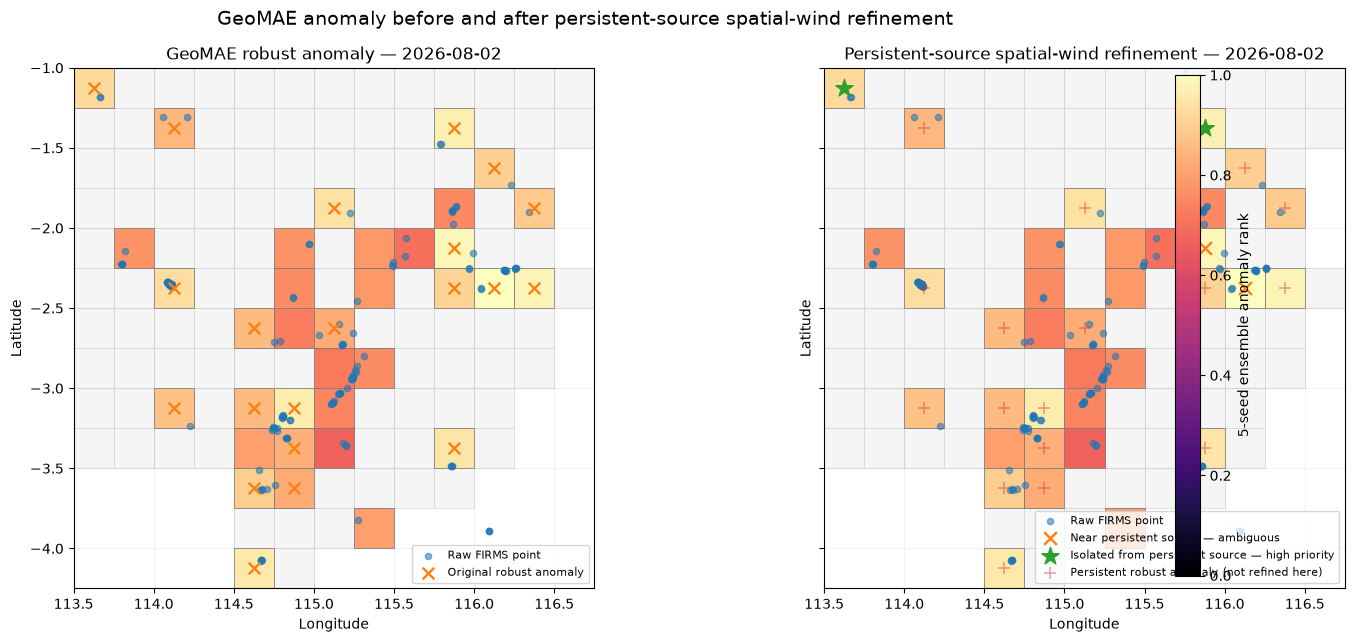

Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\persistent_source_spatial_wind_refinement\t2\figures\01_persistent_source_before_after_2026-08-02.png


In [34]:
# 15. Grid-consistent before / after map

CELL_STEP = 0.25
HALF = CELL_STEP / 2

fig, axes = plt.subplots(
    1,
    2,
    figsize=(15.5, 6.5),
    sharex=True,
    sharey=True,
)

ax_before, ax_after = axes

# Draw identical T2 grid in both panels
for ax in axes:
    for row in day.itertuples(index=False):
        rect = Rectangle(
            (row.grid_lon - HALF, row.grid_lat - HALF),
            CELL_STEP,
            CELL_STEP,
            facecolor="0.96",
            edgecolor="0.82",
            linewidth=0.45,
        )
        ax.add_patch(rect)

    # Color actual hotspot-positive cells with the original GeoMAE anomaly rank
    for row in day_hot.itertuples(index=False):
        rank = float(row.ensemble_median_rank)
        rect = Rectangle(
            (row.grid_lon - HALF, row.grid_lat - HALF),
            CELL_STEP,
            CELL_STEP,
            facecolor=plt.cm.magma(rank),
            edgecolor="0.45",
            linewidth=0.55,
        )
        ax.add_patch(rect)

    if len(firms):
        ax.scatter(
            firms["firms_lon"],
            firms["firms_lat"],
            s=20,
            alpha=0.55,
            label="Raw FIRMS point",
            zorder=4,
        )

# LEFT — original GeoMAE robust anomaly markers
if len(day_original):
    ax_before.scatter(
        day_original["grid_lon"],
        day_original["grid_lat"],
        marker="x",
        s=70,
        linewidths=1.7,
        label="Original robust anomaly",
        zorder=6,
    )

ax_before.set_title(
    f"GeoMAE robust anomaly — {TARGET_DATE.date()}"
)

# RIGHT — persistent-source refinement
if len(day_cont):
    ax_after.scatter(
        day_cont["grid_lon"],
        day_cont["grid_lat"],
        marker="o",
        s=85,
        facecolors="none",
        linewidths=1.8,
        label="Persistent continuation-like",
        zorder=7,
    )

    for row in day_cont.itertuples(index=False):
        if (
            pd.notna(row.continuation_source_lon)
            and pd.notna(row.continuation_source_lat)
        ):
            ax_after.annotate(
                "",
                xy=(row.grid_lon, row.grid_lat),
                xytext=(
                    row.continuation_source_lon,
                    row.continuation_source_lat,
                ),
                arrowprops={
                    "arrowstyle": "->",
                    "linewidth": 1.0,
                    "alpha": 0.65,
                },
                zorder=8,
            )
            ax_after.scatter(
                [row.continuation_source_lon],
                [row.continuation_source_lat],
                marker="s",
                s=42,
                alpha=0.8,
                label=None,
                zorder=8,
            )

if len(day_amb):
    ax_after.scatter(
        day_amb["grid_lon"],
        day_amb["grid_lat"],
        marker="x",
        s=85,
        linewidths=1.7,
        label="Near persistent source — ambiguous",
        zorder=7,
    )

if len(day_iso):
    ax_after.scatter(
        day_iso["grid_lon"],
        day_iso["grid_lat"],
        marker="*",
        s=170,
        linewidths=1.0,
        label="Isolated from persistent source — high priority",
        zorder=9,
    )

# Persistent robust anomalies remain visible but are outside this refinement question
persistent_day = candidates[
    candidates["date"].eq(TARGET_DATE)
    & candidates["research_group"].eq("Persistent")
]

if len(persistent_day):
    ax_after.scatter(
        persistent_day["grid_lon"],
        persistent_day["grid_lat"],
        marker="+",
        s=65,
        linewidths=1.1,
        alpha=0.45,
        label="Persistent robust anomaly (not refined here)",
        zorder=5,
    )

ax_after.set_title(
    f"Persistent-source spatial-wind refinement — {TARGET_DATE.date()}"
)

for ax in axes:
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.set_aspect("equal", adjustable="box")
    ax.grid(alpha=0.15)
    ax.set_xlim(
        day["grid_lon"].min() - HALF,
        day["grid_lon"].max() + HALF,
    )
    ax.set_ylim(
        day["grid_lat"].min() - HALF,
        day["grid_lat"].max() + HALF,
    )
    ax.legend(loc="best", fontsize=8)

sm = plt.cm.ScalarMappable(
    cmap="magma",
    norm=plt.Normalize(vmin=0, vmax=1),
)
sm.set_array([])

cbar = fig.colorbar(
    sm,
    ax=axes.ravel().tolist(),
    fraction=0.025,
    pad=0.02,
)
cbar.set_label("5-seed ensemble anomaly rank")

fig.suptitle(
    "GeoMAE anomaly before and after persistent-source spatial-wind refinement",
    fontsize=14,
)

plt.tight_layout()

fig_path = (
    FIGURE_DIR
    / f"01_persistent_source_before_after_{TARGET_DATE.date()}.png"
)
plt.savefig(fig_path, dpi=200, bbox_inches="tight")
plt.show()

print("Saved:", fig_path)

# PART F — Evidence table

For supervision, focus on **why** an Emerging anomaly is retained or deprioritized.

Useful columns:
- anomaly rank;
- nearest persistent source distance;
- how many of the previous 3 days that source was active;
- whether source was still active at `t-1`;
- `t-1` wind alignment;
- final contextual status.

Recommended wording:

> “Saya tidak langsung menyebut kandidat yang dekat sebagai false positive. Saya tandai sebagai continuation-like jika ada source cell yang sudah aktif minimal dua dari tiga hari sebelumnya, masih aktif pada t-1, lokasinya dekat, dan arah anginnya mendukung menuju candidate. Kalau tidak ada persistent source dekat, candidate menjadi spatially isolated dan saya prioritaskan sebagai anomaly yang lebih kuat.”

In [35]:
# 16. Selected-date evidence table

presentation_cols = [
    "date",
    "cell_id",
    "grid_lat",
    "grid_lon",
    "ensemble_median_rank",
    "high_seed_count",
    "nearest_persistent_source_km",
    "nearest_persistent_source_cell_id",
    "nearest_persistent_source_active_days_prev3",
    "nearest_persistent_source_active_t1",
    "nearest_persistent_source_wind_alignment_t1",
    "continuation_source_distance_km",
    "continuation_source_active_days_prev3",
    "continuation_source_wind_alignment_t1",
    "refinement_status",
    "retained_after_refinement",
    "refined_high_priority",
]

display(
    day_refined[presentation_cols]
    .sort_values(
        ["refined_high_priority", "ensemble_median_rank"],
        ascending=[False, False],
    )
)

,date,cell_id,grid_lat,grid_lon,ensemble_median_rank,high_seed_count,nearest_persistent_source_km,nearest_persistent_source_cell_id,nearest_persistent_source_active_days_prev3,nearest_persistent_source_active_t1,nearest_persistent_source_wind_alignment_t1,continuation_source_distance_km,continuation_source_active_days_prev3,continuation_source_wind_alignment_t1,refinement_status,retained_after_refinement,refined_high_priority
0,2026-08-02,regional025_12_31,-1.375,115.875,0.969925,5,55.597540,regional025_10_31,3,1,0.684505,NaN,NaN,NaN,isolated_from_persistent_source,True,True
1,2026-08-02,regional025_13_22,-1.125,113.625,0.924812,5,87.888539,regional025_12_25,2,0,0.993505,NaN,NaN,NaN,isolated_from_persistent_source,True,True
2,2026-08-02,regional025_8_32,-2.375,116.125,1.000000,5,27.774891,regional025_8_31,2,0,-0.559678,NaN,NaN,NaN,near_persistent_source_ambiguous,True,False
3,2026-08-02,regional025_9_31,-2.125,115.875,0.984962,5,27.779653,regional025_9_30,3,1,-0.939690,NaN,NaN,NaN,near_persistent_source_ambiguous,True,False


In [36]:
# 17. Top high-priority isolated candidates across August

high_priority = (
    refined[refined["refined_high_priority"]]
    .sort_values(
        [
            "ensemble_median_rank",
            "high_seed_count",
            "nearest_persistent_source_km",
        ],
        ascending=[False, False, False],
        na_position="first",
    )
    .copy()
)

print("High-priority Emerging anomalies isolated from persistent sources:", len(high_priority))

display(
    high_priority[
        [
            "date",
            "cell_id",
            "grid_lat",
            "grid_lon",
            "ensemble_median_rank",
            "high_seed_count",
            "nearest_persistent_source_km",
            "nearest_persistent_source_active_days_prev3",
            "nearest_persistent_source_active_t1",
            "nearest_persistent_source_wind_alignment_t1",
        ]
    ].head(30)
)

High-priority Emerging anomalies isolated from persistent sources: 22


,date,cell_id,grid_lat,grid_lon,ensemble_median_rank,high_seed_count,nearest_persistent_source_km,nearest_persistent_source_active_days_prev3,nearest_persistent_source_active_t1,nearest_persistent_source_wind_alignment_t1
6,2026-08-04,regional025_5_22,-3.125,113.625,0.977444,5,100.194168,2,0,-0.690342
0,2026-08-02,regional025_12_31,-1.375,115.875,0.969925,5,55.597540,3,1,0.684505
47,2026-08-09,regional025_12_31,-1.375,115.875,0.969925,5,55.597540,3,1,0.868688
26,2026-08-06,regional025_4_31,-3.375,115.875,0.947368,5,78.548051,2,1,0.030190
80,2026-08-15,regional025_7_33,-2.625,116.375,0.947368,5,55.539200,2,1,-0.307450
5,2026-08-04,regional025_12_28,-1.375,115.125,0.939850,5,87.903267,2,0,0.572002
12,2026-08-05,regional025_12_22,-1.375,113.625,0.932331,5,55.581531,2,1,-0.486694
1,2026-08-02,regional025_13_22,-1.125,113.625,0.924812,5,87.888539,2,0,0.993505
4,2026-08-04,regional025_12_27,-1.375,114.875,0.924812,5,83.372296,2,0,-0.095123
11,2026-08-05,regional025_11_33,-1.625,116.375,0.909774,5,62.136707,2,1,-0.034821


In [37]:
# 18. Export outputs

REFINED_PATH = (
    EXPORT_DIR / "august_emerging_persistent_source_refined.csv"
)
HIGH_PRIORITY_PATH = (
    EXPORT_DIR / "august_emerging_isolated_from_persistent_source.csv"
)
PAIR_PATH = (
    EXPORT_DIR / "emerging_candidate_persistent_source_pairs.csv"
)
SENSITIVITY_PATH = (
    EXPORT_DIR / "persistent_source_refinement_sensitivity.csv"
)
SUMMARY_PATH = (
    EXPORT_DIR / "persistent_source_refinement_summary.csv"
)

refined.to_csv(REFINED_PATH, index=False)
high_priority.to_csv(HIGH_PRIORITY_PATH, index=False)
persistent_pairs.to_csv(PAIR_PATH, index=False)
sensitivity.to_csv(SENSITIVITY_PATH, index=False)
summary_table.to_csv(SUMMARY_PATH, index=False)

print("Saved:")
print("-", REFINED_PATH)
print("-", HIGH_PRIORITY_PATH)
print("-", PAIR_PATH)
print("-", SENSITIVITY_PATH)
print("-", SUMMARY_PATH)

Saved:
- c:\Users\Asus\Documents\skripsi-karhut\model_results\persistent_source_spatial_wind_refinement\t2\exports\august_emerging_persistent_source_refined.csv
- c:\Users\Asus\Documents\skripsi-karhut\model_results\persistent_source_spatial_wind_refinement\t2\exports\august_emerging_isolated_from_persistent_source.csv
- c:\Users\Asus\Documents\skripsi-karhut\model_results\persistent_source_spatial_wind_refinement\t2\exports\emerging_candidate_persistent_source_pairs.csv
- c:\Users\Asus\Documents\skripsi-karhut\model_results\persistent_source_spatial_wind_refinement\t2\exports\persistent_source_refinement_sensitivity.csv
- c:\Users\Asus\Documents\skripsi-karhut\model_results\persistent_source_spatial_wind_refinement\t2\exports\persistent_source_refinement_summary.csv


# What to send back after Run All

Please send the executed notebook or screenshots of these three outputs:

1. **`NB29C PERSISTENT-SOURCE SPATIAL-WIND REFINEMENT`** count summary;
2. the **before / after 0.25° grid map**;
3. the **selected-date evidence table**.

The result to look for is not a predetermined candidate count. We want to see whether the persistent-source rule produces a sensible separation between:
- nearby continuation-like Emerging events;
- nearby but ambiguous events;
- genuinely isolated Emerging robust anomalies.